In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve
)

In [7]:
model_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.7331,
        "Precision": 0.4983,
        "Recall": 0.7914,
        "F1 Score": 0.6116,
        "ROC-AUC": 0.8418
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.7388,
        "Precision": 0.5051,
        "Recall": 0.7888,
        "F1 Score": 0.6159,
        "ROC-AUC": 0.8280
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.7686,
        "Precision": 0.5482,
        "Recall": 0.7299,
        "F1 Score": 0.6261,
        "ROC-AUC": 0.8405
    },
    {
        "Model": "Gradient Boosting",
        "Accuracy": 0.8041,
        "Precision": 0.6701,
        "Recall": 0.5160,
        "F1 Score": 0.5831,
        "ROC-AUC": 0.8457
    },
    {
        "Model": "LightGBM",
        "Accuracy": 0.7608,
        "Precision": 0.5359,
        "Recall": 0.7380,
        "F1 Score": 0.6209,
        "ROC-AUC": 0.8326
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.8034,
        "Precision": 0.6611,
        "Recall": 0.5321,
        "F1 Score": 0.5896,
        "ROC-AUC": 0.8421
    },
    {
        "Model": "Gaussian Naive Bayes",
        "Accuracy": 0.7026,
        "Precision": 0.4661,
        "Recall": 0.8262,
        "F1 Score": 0.5959,
        "ROC-AUC": 0.8115
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": 0.7587,
        "Precision": 0.5310,
        "Recall": 0.7781,
        "F1 Score": 0.6312,
        "ROC-AUC": 0.8430
    }
]

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.7587,0.5310,0.7781,0.6312,0.8430
1,Random Forest,0.7686,0.5482,0.7299,0.6261,0.8405
2,LightGBM,0.7608,0.5359,0.7380,0.6209,0.8326
3,Decision Tree,0.7388,0.5051,0.7888,0.6159,0.8280
4,Logistic Regression,0.7331,0.4983,0.7914,0.6116,0.8418
5,Gaussian Naive Bayes,0.7026,0.4661,0.8262,0.5959,0.8115
6,XGBoost,0.8034,0.6611,0.5321,0.5896,0.8421
7,Gradient Boosting,0.8041,0.6701,0.5160,0.5831,0.8457


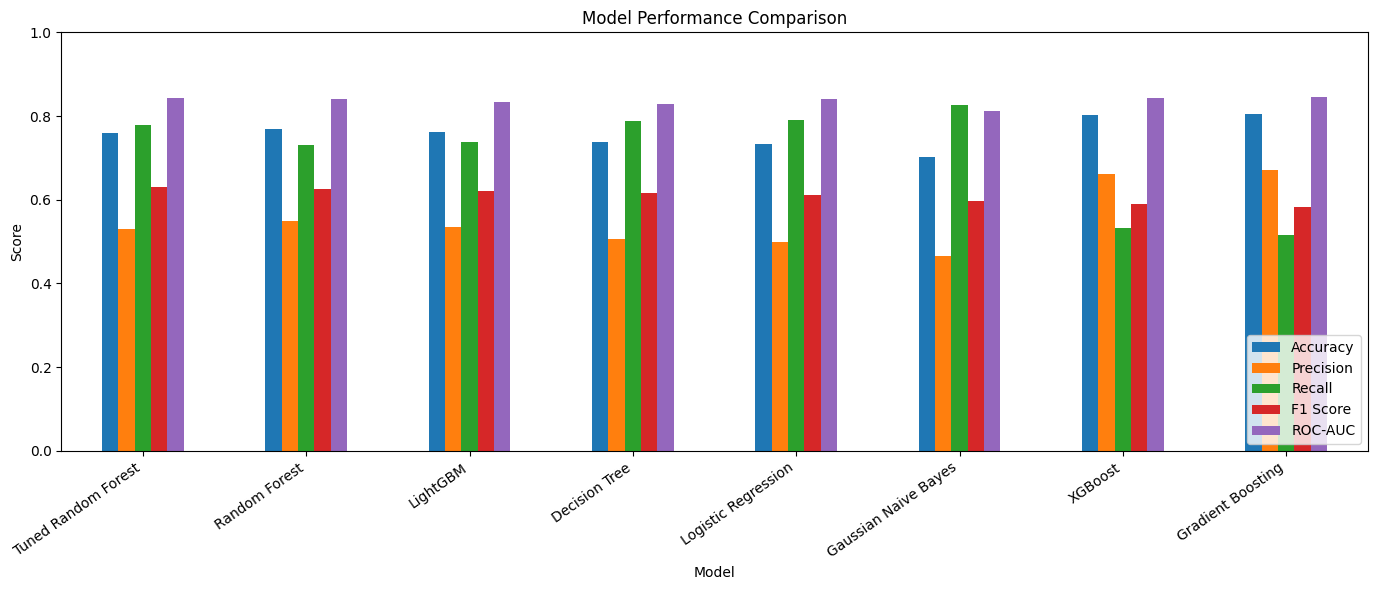

In [10]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 6),
    ylim=(0, 1)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
import joblib

best_model = joblib.load(
    "../models/tuned_random_forest.pkl"
)

In [16]:
import pandas as pd

train_df = pd.read_csv("../data/processed/train.csv")
test_df = pd.read_csv("../data/processed/test.csv")

X_test = test_df.drop(columns=["Churn", "customerID"], errors="ignore")

y_test = test_df["Churn"]

In [17]:
y_pred = best_model.predict(X_test)

print("Predictions:", y_pred[:10])
print("Test samples:", len(X_test))

Predictions: [0 1 0 1 0 1 1 0 0 1]
Test samples: 1409


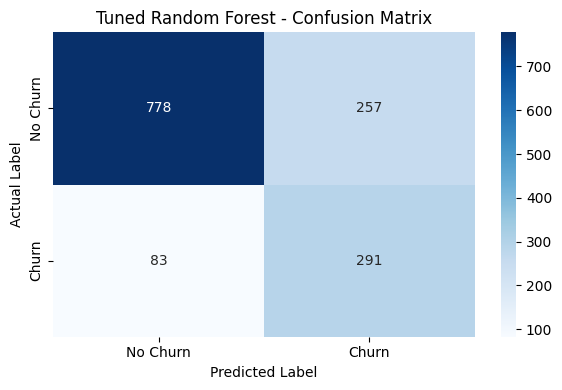

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



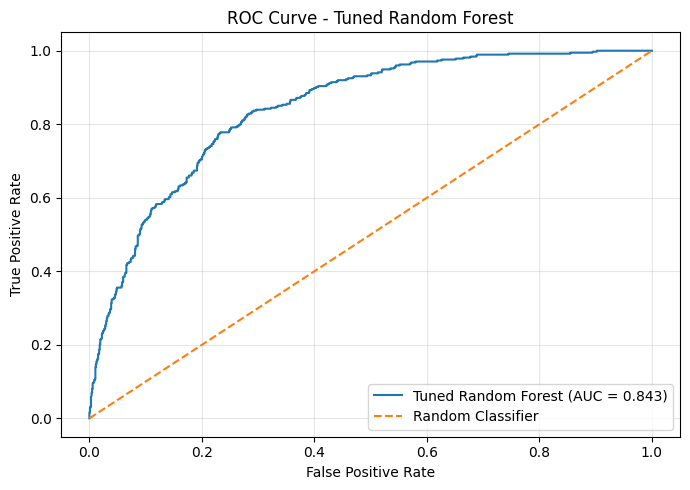

ROC-AUC Score: 0.8430


In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Tuned Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

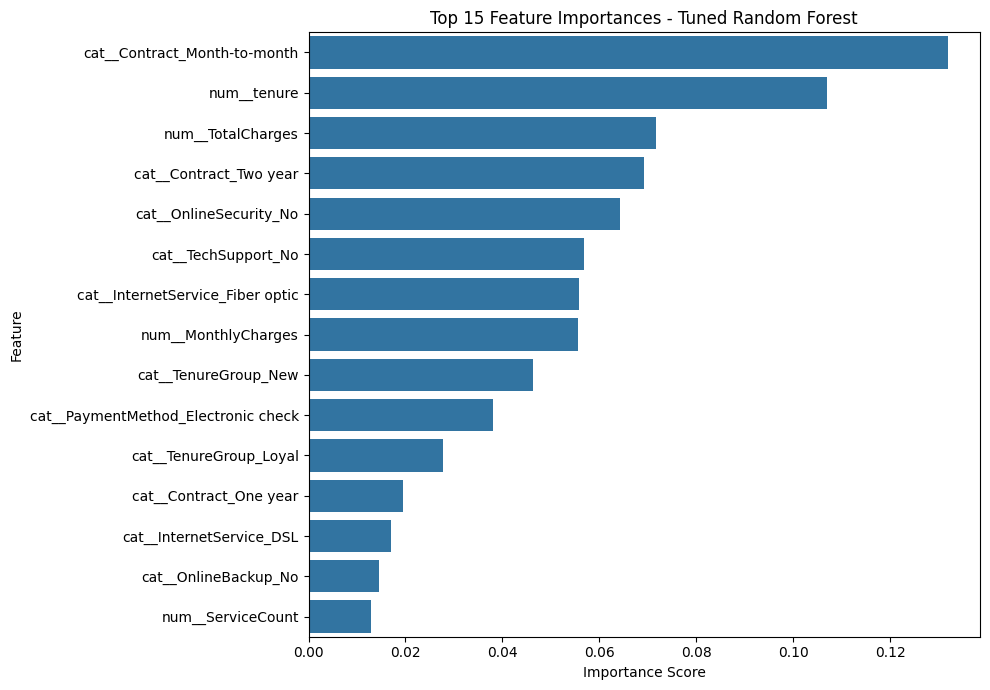

,Feature,Importance
37,cat__Contract_Month-to-month,0.131926
1,num__tenure,0.106922
3,num__TotalCharges,0.071760
39,cat__Contract_Two year,0.069208
19,cat__OnlineSecurity_No,0.064265
28,cat__TechSupport_No,0.056866
17,cat__InternetService_Fiber optic,0.055764
2,num__MonthlyCharges,0.055634
49,cat__TenureGroup_New,0.046271
44,cat__PaymentMethod_Electronic check,0.038136


In [21]:
# Get the fitted preprocessor and Random Forest
preprocessor = best_model.named_steps["preprocessor"]
rf_model = best_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Display the top 15 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

top_features

In [23]:
from pathlib import Path

# Create reports folder at the project root
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison
results_df.to_csv(
    reports_dir / "model_comparison.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    reports_dir / "feature_importance.csv",
    index=False
)

print("Model comparison saved:", reports_dir / "model_comparison.csv")
print("Feature importance saved:", reports_dir / "feature_importance.csv")

Model comparison saved: ..\reports\model_comparison.csv
Feature importance saved: ..\reports\feature_importance.csv


### Model Analysis and Findings

Multiple classification algorithms were evaluated for telecom customer churn prediction using accuracy, precision, recall, F1-score, and ROC-AUC.

The tuned Random Forest achieved an F1-score of approximately 0.631 and a ROC-AUC of 0.843. Its churn-class recall was approximately 78%, indicating that it identified most customers who actually churned, while churn precision was approximately 53%.

Feature importance analysis identified month-to-month contracts, customer tenure, total charges, contract duration, online security, and technical support as important predictive features.

These findings can help prioritize customers for retention campaigns. The model's predictions should be evaluated alongside the costs of missed churners and unnecessary retention offers.

*Note: Results are based on the current experimental test-set evaluation and should not be described as an independent final estimate because the test set was reused during model development.*